# 25 — Experimento com previsão independente e quantitativo institucional

Esta etapa compara duas bases de informação: consumo passado, calendário e cardápio (A); e as mesmas fontes com o quantitativo institucional (B). As versões C e D acrescentam às respectivas previsões margens escolhidas na simulação de 2024. A referência institucional usada diretamente constitui a comparação.

O ajuste gerencial é zero: não existem regras da nutricionista documentadas para este experimento. C/D são planos com margem e não medem a expertise profissional. Clima não entra nesta comparação. A/C podem ser emitidos sem quantitativo futuro; B/D exigem essa informação disponível.

Os modelos são ajustados em 2023–2025. Cada previsão histórica usa somente alvos anteriores à sexta-feira de origem. A calibração de margens usa erros anteriores da própria linha. Em 2026, o consumo de semanas anteriores pode compor o histórico, mas nenhum alvo de 2026 ajusta o modelo ou a margem. O diagnóstico de 2026 é exploratório porque esses resultados já foram examinados no projeto.

Os resultados e as previsões enviadas anteriormente são preservados. Reexecutar esta etapa verifica o conjunto congelado por hashes, sem refazer a escolha de regras.


In [1]:
from pathlib import Path
import subprocess, sys, os
ROOT=Path(r"F:\PRODUTO_MESTRADO")
env=dict(os.environ,PYTHONIOENCODING="utf-8",PYTHONDONTWRITEBYTECODE="1")
run=subprocess.run([sys.executable,str(ROOT/"scripts/experimentar_previsao_independente_reservas.py")],cwd=ROOT,env=env,capture_output=True,text=True,encoding="utf-8")
print(run.stdout)
if run.returncode: raise RuntimeError(run.stderr)


Experimento existente preservado; resultados conferidos por hash.
 ano versao                              metodo  n_datas  MAE_refeicoes  WAPE_pct  vies_refeicoes  excesso_potencial  deficit_potencial  dias_deficit  perda_hipotetica_2a1
2023      A           A — Previsão independente      120          23.84     22.80            3.32             1630.0             1231.0            64                 34.10
2024      A           A — Previsão independente      122          26.20     15.66           -4.16             1344.0             1852.0            62                 41.38
2025      A           A — Previsão independente      155          21.27     15.37            5.70             2090.0             1207.0            66                 29.06
2026      A           A — Previsão independente      123          35.97     21.51          -14.28             1334.0             3090.0            86                 61.09
2023      B       B — Previsão com quantitativo      120          20.87   

,ano,versao,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1
0,2023,A,A — Previsão independente,120,23.84,22.80,3.32,1630.0,1231.0,64,34.10
1,2024,A,A — Previsão independente,122,26.20,15.66,-4.16,1344.0,1852.0,62,41.38
2,2025,A,A — Previsão independente,155,21.27,15.37,5.70,2090.0,1207.0,66,29.06
3,2026,A,A — Previsão independente,123,35.97,21.51,-14.28,1334.0,3090.0,86,61.09
4,2023,B,B — Previsão com quantitativo,120,20.87,19.95,2.55,1405.0,1099.0,68,30.02
5,2024,B,B — Previsão com quantitativo,122,25.25,15.10,-3.52,1326.0,1755.0,63,39.64
6,2025,B,B — Previsão com quantitativo,155,20.36,14.71,4.77,1948.0,1208.0,70,28.15
7,2026,B,B — Previsão com quantitativo,123,34.98,20.91,-13.14,1343.0,2959.0,86,59.03
8,2023,C,C — Plano independente com margem,120,25.16,24.06,13.32,2309.0,710.0,40,31.08
9,2024,C,C — Plano independente com margem,122,26.77,16.01,5.84,1989.0,1277.0,48,37.24


,ano,linha,politica,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1
0,2023,A,Fixa +10,120,25.16,24.06,13.32,2309.0,710.0,40,31.08
1,2023,A,Quantil global 2/3,120,26.37,25.21,15.10,2488.0,676.0,35,32.00
2,2023,A,Quantil por dia 2/3,120,25.97,24.83,14.45,2425.0,691.0,35,31.72
3,2023,A,Quantil por dia e período 2/3,120,25.97,24.83,14.45,2425.0,691.0,35,31.72
4,2024,A,Fixa +10,122,26.77,16.01,5.84,1989.0,1277.0,48,37.24
5,2024,A,Quantil global 2/3,122,28.44,17.01,10.74,2390.0,1080.0,39,37.30
6,2024,A,Quantil por dia 2/3,122,29.05,17.37,10.87,2435.0,1109.0,38,38.14
7,2024,A,Quantil por dia e período 2/3,122,29.71,17.77,11.71,2527.0,1098.0,38,38.71
8,2025,A,Fixa +10,155,23.99,17.34,15.70,3076.0,643.0,45,28.14
9,2025,A,Quantil global 2/3,155,25.29,18.28,18.49,3393.0,527.0,40,28.69


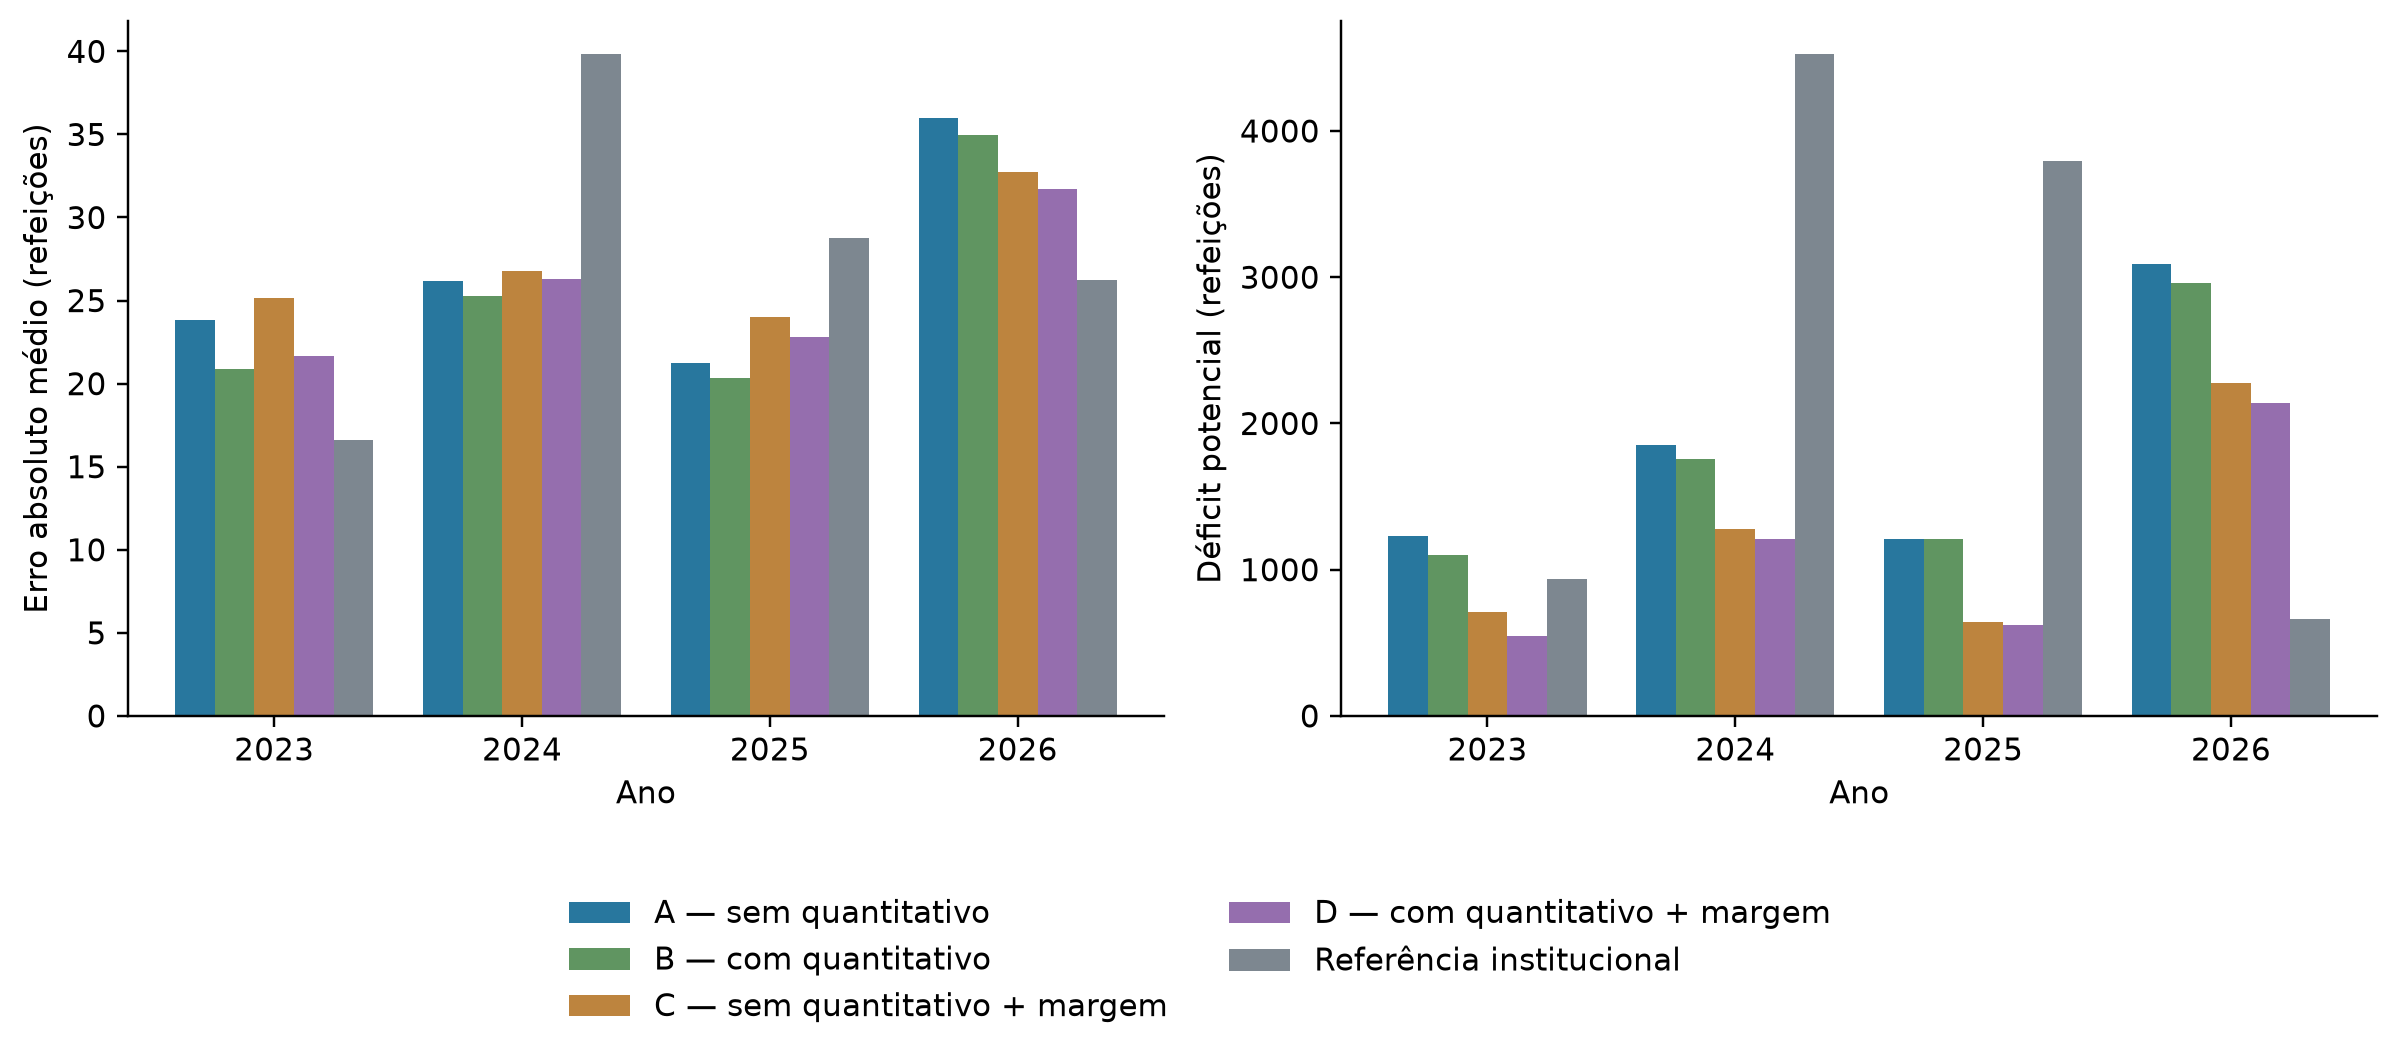

In [2]:
import pandas as pd, json
from IPython.display import display, Image
OUT=ROOT/"resultados/experimento_independente_reservas_20261003"
metrics=pd.read_csv(OUT/"metricas_quatro_alternativas.csv")
display(metrics.round(2))
display(pd.read_csv(OUT/"metricas_politicas_margem.csv").round(2))
display(Image(filename=str(OUT/"figuras/erro_deficit_quatro_alternativas.png")))


In [3]:
checks=json.loads((OUT/"checagens.json").read_text(encoding="utf-8"))
display(checks)
display(pd.read_csv(OUT/"origens_e_treinos.csv").tail())
display(pd.read_csv(OUT/"cobertura_margens.csv").round(2))


{'historico_A_reproduzido': True,
 'A_C_sem_quantitativo_nos_preditores_ou_residuos': True,
 'features_invariantes_consumo_futuro_e_reservas_gold_2026': True,
 'mesmo_treino_A_B': True,
 'n_treino': 500,
 'n_quantitativos_ausentes_treino': 42,
 'n_preditores_A': 71,
 'n_preditores_B': 72,
 'coorte_por_ano': {'2023': 120, '2024': 122, '2025': 155, '2026': 123},
 'margens_selecionadas': {'A': 'Fixa +10', 'B': 'Fixa +10'},
 'ajuste_gerencial': 0,
 '2026_alvos_na_calibracao': False,
 'previsoes_anteriores_sha256_preservadas': {'resultados\\validacao_setembro_2026\\previsoes_setembro_2026_congeladas.csv': 'b1eab67d2ff66263f715adf66b4658e0918d52bb030aa8639eca81d11725fd6a',
  'resultados\\validacao_prospectiva_20261005\\previsoes_congeladas_20261005_20261009.csv': '06a0733d517d39b555253821d581fdad64478f7b8293f789591e7b3118dbb949',
  'resultados\\validacao_prospectiva_20261005\\emissoes\\20261003_candidato_hibrido_v2\\previsoes_congeladas.csv': 'fe5146a948631ab3a02c004d208ddd5bd4b15ba42c8cf8fe

,origem,n_treino_A_B,ultimo_alvo_treino,n_quantitativos_ausentes_treino,n_alvos_A,n_alvos_B
99,2025-11-14,482,2025-11-13,40,2,2
100,2025-11-21,484,2025-11-18,40,3,3
101,2025-11-28,488,2025-11-27,40,5,5
102,2025-12-05,492,2025-12-04,40,5,5
103,2025-12-12,497,2025-12-11,40,2,0


,ano,linha,politica,fonte_margem,n_datas,margem_media
0,2023,A,Fixa +10,fixa,120,10.00
1,2023,A,Quantil global 2/3,fixa por amostra insuficiente,33,10.00
2,2023,A,Quantil global 2/3,global,87,12.43
3,2023,A,Quantil por dia 2/3,dia da semana,19,8.87
4,2023,A,Quantil por dia 2/3,fixa por amostra insuficiente,33,10.00
5,2023,A,Quantil por dia 2/3,global,68,12.27
6,2023,A,Quantil por dia e período 2/3,dia da semana,19,8.87
7,2023,A,Quantil por dia e período 2/3,fixa por amostra insuficiente,33,10.00
8,2023,A,Quantil por dia e período 2/3,global,68,12.27
9,2023,B,Fixa +10,fixa,120,10.00


## Como interpretar a comparação

Comparar todas as alternativas nas mesmas datas de cada ano. Há 120, 122, 155 e 123 datas, respectivamente, em 2023–2026. Essas 397 datas históricas diferem da coorte de 390 datas da competição anterior. Previsões são arredondadas para cima para formar planos inteiros.

O erro absoluto médio mede a distância entre plano e consumo observado. Excesso e déficit representam diferenças potenciais; não comprovam desperdício físico ou refeições não atendidas. A perda que pesa o déficit duas vezes é uma hipótese de avaliação, não uma penalidade contratual.

Em 2023–2025, o quantitativo deriva de reservas dos estudantes; em 2026, da estimativa da nutricionista. Uma vantagem de B/D não comprova capacidade de antecipar compras sem essa informação. Uma vantagem de C precisa ser examinada também quanto ao aumento de excesso. Nenhuma regra deve substituir silenciosamente as emissões já enviadas.

O teste de uso pela gestão e a confirmação em datas ainda futuras são próximos passos. Quando documentadas, as regras profissionais precisam informar condição, ajuste, fonte e momento de disponibilidade, sem introduzir em A/C o quantitativo por outro nome.


## Teste secundário: margens com erros recentes

O teste abaixo permite somente à margem incorporar erros já observados de 2026, anteriores à sexta de origem. Os estimadores continuam ajustados em 2023–2025. Isso difere do primeiro protocolo, cuja calibração exclui 2026. A escolha histórica permaneceu +10; não foi adotada uma margem adaptativa. Nenhuma das políticas móveis superou o erro da referência institucional de 2026.


In [4]:
run=subprocess.run([sys.executable,str(ROOT/"scripts/experimentar_margens_adaptativas.py")],cwd=ROOT,env=env,capture_output=True,text=True,encoding="utf-8")
if run.returncode: raise RuntimeError(run.stderr)
AD=ROOT/"resultados/experimento_margens_adaptativas_20261003"
display(json.loads((AD/"selecao.json").read_text(encoding="utf-8")))
display(pd.read_csv(AD/"metricas_todas_politicas.csv").round(2))
print("Seleção histórica: margem fixa +10. Nenhuma atualização adaptativa foi adotada.")


{'politicas': {'A': 'Fixa +10', 'B': 'Fixa +10'},
 'selecao': 2024,
 'conferencia': 2025}

,ano,linha,politica,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1
0,2023,A,Fixa +10,120,25.16,24.06,13.32,2309.0,710.0,40,31.08
1,2023,A,Global últimos 60,120,26.48,25.32,15.32,2508.0,670.0,36,32.07
2,2023,A,Global últimos 120,120,26.37,25.21,15.10,2488.0,676.0,35,32.00
3,2023,A,Dia da semana últimos 120,120,25.97,24.83,14.45,2425.0,691.0,35,31.72
4,2024,A,Fixa +10,122,26.77,16.01,5.84,1989.0,1277.0,48,37.24
5,2024,A,Global últimos 60,122,31.39,18.77,14.43,2795.0,1034.0,37,39.86
6,2024,A,Global últimos 120,122,29.16,17.43,11.86,2502.0,1055.0,37,37.80
7,2024,A,Dia da semana últimos 120,122,30.64,18.32,12.70,2644.0,1094.0,36,39.61
8,2025,A,Fixa +10,155,23.99,17.34,15.70,3076.0,643.0,45,28.14
9,2025,A,Global últimos 60,155,24.78,17.91,16.24,3179.0,662.0,44,29.05


Seleção histórica: margem fixa +10. Nenhuma atualização adaptativa foi adotada.
